# Python DA Assignment 2 - Data Visualization

## 1) Loading the Taxis Dataset

In [19]:
import seaborn as sns

# Load the taxis dataset
df = sns.load_dataset("taxis")

In [20]:
df.head()

,pickup,dropoff,passengers,distance,fare,tip,tolls,total,color,payment,pickup_zone,dropoff_zone,pickup_borough,dropoff_borough
0,2019-03-23 20:21:09,2019-03-23 20:27:24,1,1.60,7.0,2.15,0.0,12.95,yellow,credit card,Lenox Hill West,UN/Turtle Bay South,Manhattan,Manhattan
1,2019-03-04 16:11:55,2019-03-04 16:19:00,1,0.79,5.0,0.00,0.0,9.30,yellow,cash,Upper West Side South,Upper West Side South,Manhattan,Manhattan
2,2019-03-27 17:53:01,2019-03-27 18:00:25,1,1.37,7.5,2.36,0.0,14.16,yellow,credit card,Alphabet City,West Village,Manhattan,Manhattan
3,2019-03-10 01:23:59,2019-03-10 01:49:51,1,7.70,27.0,6.15,0.0,36.95,yellow,credit card,Hudson Sq,Yorkville West,Manhattan,Manhattan
4,2019-03-30 13:27:42,2019-03-30 13:37:14,3,2.16,9.0,1.10,0.0,13.40,yellow,credit card,Midtown East,Yorkville West,Manhattan,Manhattan


In [21]:
df.tail()

,pickup,dropoff,passengers,distance,fare,tip,tolls,total,color,payment,pickup_zone,dropoff_zone,pickup_borough,dropoff_borough
6428,2019-03-31 09:51:53,2019-03-31 09:55:27,1,0.75,4.5,1.06,0.0,6.36,green,credit card,East Harlem North,Central Harlem North,Manhattan,Manhattan
6429,2019-03-31 17:38:00,2019-03-31 18:34:23,1,18.74,58.0,0.00,0.0,58.80,green,credit card,Jamaica,East Concourse/Concourse Village,Queens,Bronx
6430,2019-03-23 22:55:18,2019-03-23 23:14:25,1,4.14,16.0,0.00,0.0,17.30,green,cash,Crown Heights North,Bushwick North,Brooklyn,Brooklyn
6431,2019-03-04 10:09:25,2019-03-04 10:14:29,1,1.12,6.0,0.00,0.0,6.80,green,credit card,East New York,East Flatbush/Remsen Village,Brooklyn,Brooklyn
6432,2019-03-13 19:31:22,2019-03-13 19:48:02,1,3.85,15.0,3.36,0.0,20.16,green,credit card,Boerum Hill,Windsor Terrace,Brooklyn,Brooklyn


In [4]:
df.shape

(6433, 14)

In [6]:
df.columns

Index(['pickup', 'dropoff', 'passengers', 'distance', 'fare', 'tip', 'tolls',
       'total', 'color', 'payment', 'pickup_zone', 'dropoff_zone',
       'pickup_borough', 'dropoff_borough'],
      dtype='str')

In [22]:
df.dtypes

pickup             datetime64[us]
dropoff            datetime64[us]
passengers                  int64
distance                  float64
fare                      float64
tip                       float64
tolls                     float64
total                     float64
color                         str
payment                       str
pickup_zone                   str
dropoff_zone                  str
pickup_borough                str
dropoff_borough               str
dtype: object

In [8]:
df.describe()

,pickup,dropoff,passengers,distance,fare,tip,tolls,total
count,6433,6433,6433.000000,6433.000000,6433.000000,6433.00000,6433.000000,6433.000000
mean,2019-03-16 08:31:28.514223,2019-03-16 08:45:49.491216,1.539251,3.024617,13.091073,1.97922,0.325273,18.517794
min,2019-02-28 23:29:03,2019-02-28 23:32:35,0.000000,0.000000,1.000000,0.00000,0.000000,1.300000
25%,2019-03-08 15:50:34,2019-03-08 16:12:51,1.000000,0.980000,6.500000,0.00000,0.000000,10.800000
50%,2019-03-15 21:46:58,2019-03-15 22:06:44,1.000000,1.640000,9.500000,1.70000,0.000000,14.160000
75%,2019-03-23 17:41:38,2019-03-23 17:51:56,2.000000,3.210000,15.000000,2.80000,0.000000,20.300000
max,2019-03-31 23:43:45,2019-04-01 00:13:58,6.000000,36.700000,150.000000,33.20000,24.020000,174.820000
std,NaN,NaN,1.203768,3.827867,11.551804,2.44856,1.415267,13.815570


## 2) Handling Missing Values 

In [23]:
df.isnull().sum()

pickup              0
dropoff             0
passengers          0
distance            0
fare                0
tip                 0
tolls               0
total               0
color               0
payment            44
pickup_zone        26
dropoff_zone       45
pickup_borough     26
dropoff_borough    45
dtype: int64

In [ ]:
number_columns = df.select_dtypes(include='number').columns
category_columns = df.select_dtypes(include='object').columns
for col in number_columns:
    df[col] = df[col].fillna(df[col].median())
for col in category_columns:
    df[col] = df[col].fillna(df[col].mode()[0])

In [25]:
df.isnull().sum()

pickup             0
dropoff            0
passengers         0
distance           0
fare               0
tip                0
tolls              0
total              0
color              0
payment            0
pickup_zone        0
dropoff_zone       0
pickup_borough     0
dropoff_borough    0
dtype: int64

In [26]:
df.dropna(inplace=True)

In [27]:
df.isnull().sum()

pickup             0
dropoff            0
passengers         0
distance           0
fare               0
tip                0
tolls              0
total              0
color              0
payment            0
pickup_zone        0
dropoff_zone       0
pickup_borough     0
dropoff_borough    0
dtype: int64

## 3) Visualizations using Matplotlib/Pandas Plot:

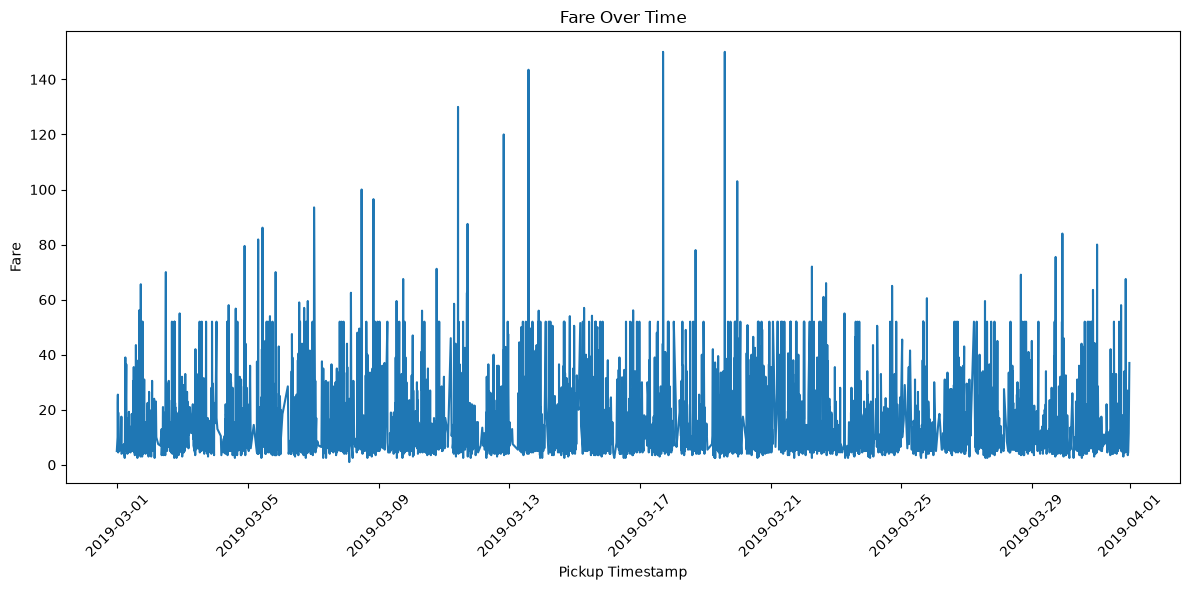

In [28]:
import matplotlib.pyplot as plt
import pandas as pd

# Convert pickup column into datetime format
df['pickup'] = pd.to_datetime(df['pickup'])

# Sort the data by pickup timestamp
df = df.sort_values(by='pickup')

# Create line chart
plt.figure(figsize=(12, 6))
plt.plot(df['pickup'], df['fare'])

# Add chart title and labels
plt.title('Fare Over Time')
plt.xlabel('Pickup Timestamp')
plt.ylabel('Fare')

# Display the chart
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

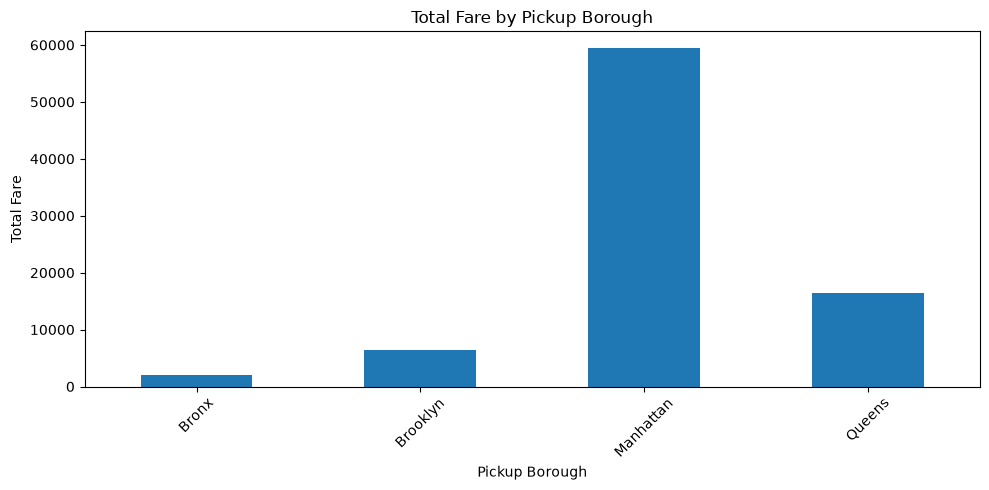

In [53]:
import matplotlib.pyplot as plt

# Group data by pickup_borough and calculate total fare
borough_fare = df.groupby('pickup_borough')['fare'].sum()

# Create bar chart
plt.figure(figsize=(10, 5))
borough_fare.plot(kind='bar')

# Add title and labels
plt.title('Total Fare by Pickup Borough')
plt.xlabel('Pickup Borough')
plt.ylabel('Total Fare')

# Display the chart
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

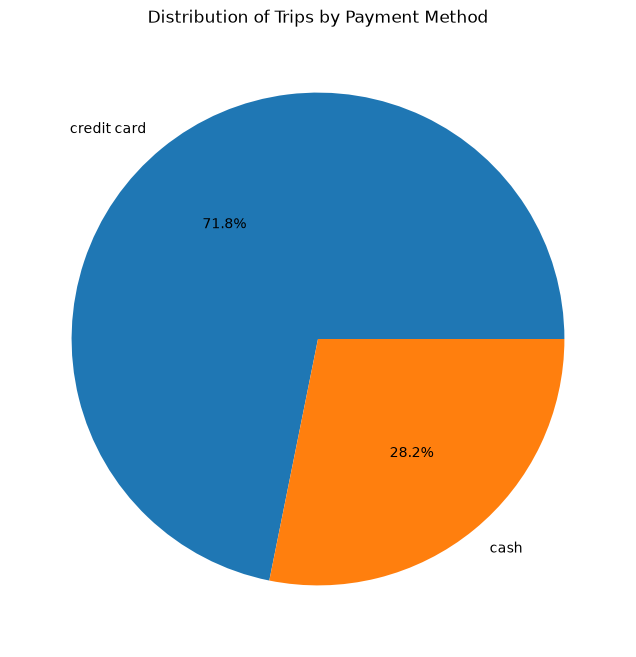

In [30]:
import matplotlib.pyplot as plt

# Count trips for each payment method
payment_counts = df['payment'].value_counts()

# Create pie chart
plt.figure(figsize=(8, 8))
plt.pie(payment_counts, labels=payment_counts.index, autopct='%1.1f%%')

# Add title
plt.title('Distribution of Trips by Payment Method')

# Display chart
plt.show()

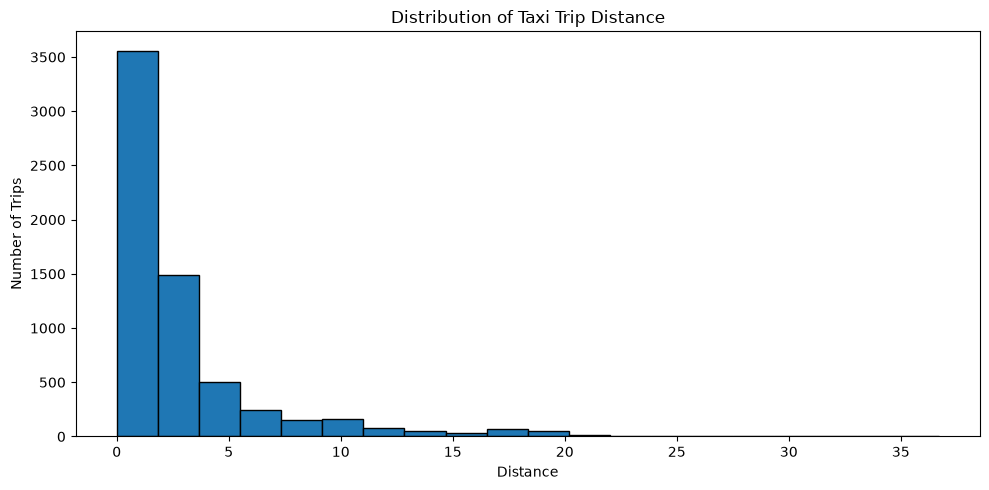

In [31]:
import matplotlib.pyplot as plt

# Create histogram
plt.figure(figsize=(10, 5))
plt.hist(df['distance'], bins=20, edgecolor='black')

# Add title and labels
plt.title('Distribution of Taxi Trip Distance')
plt.xlabel('Distance')
plt.ylabel('Number of Trips')

# Display the histogram
plt.tight_layout()
plt.show()

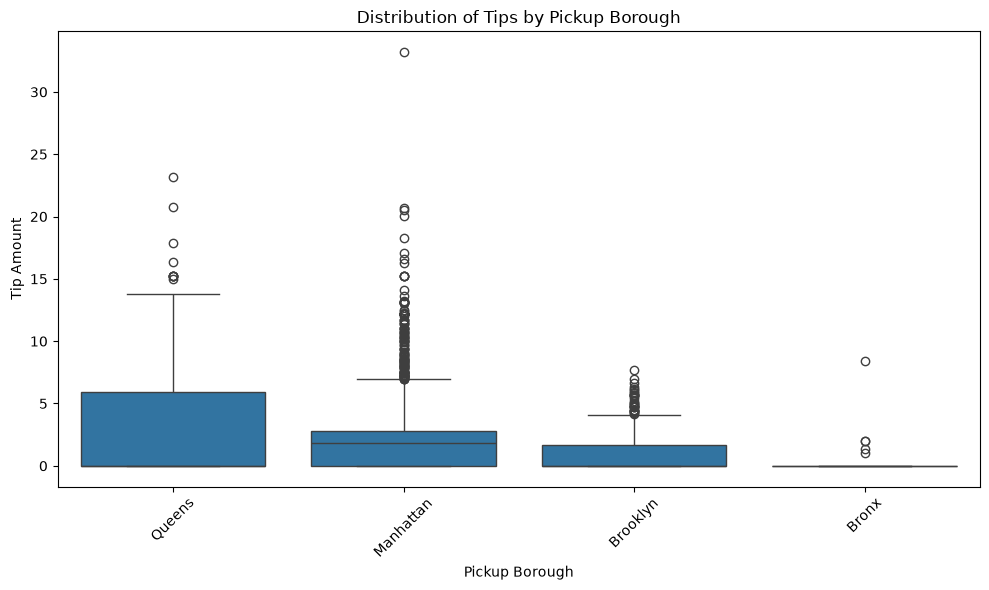

In [32]:
import matplotlib.pyplot as plt
import seaborn as sns

# Create box plot
plt.figure(figsize=(10, 6))
sns.boxplot(x='pickup_borough', y='tip', data=df)

# Add title and labels
plt.title('Distribution of Tips by Pickup Borough')
plt.xlabel('Pickup Borough')
plt.ylabel('Tip Amount')

# Display the plot
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## Visualizations using Seaborn: 

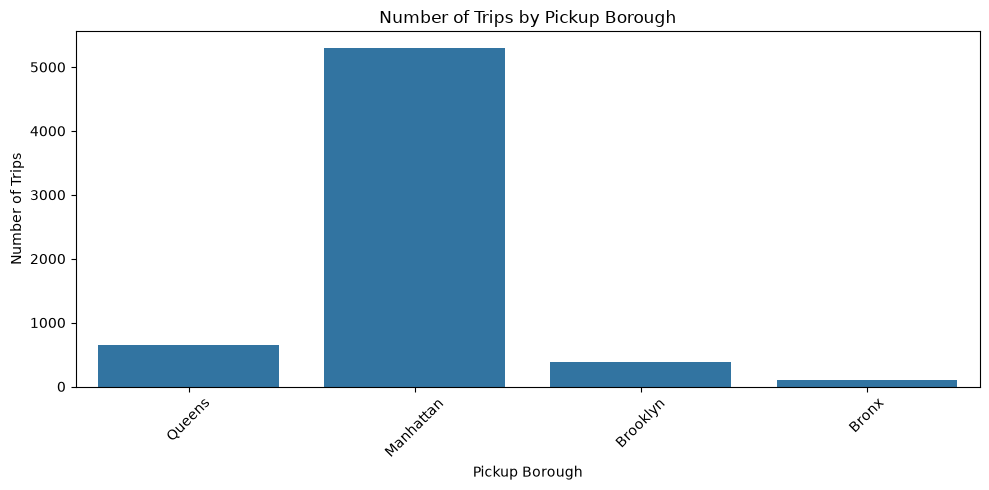

In [33]:
import matplotlib.pyplot as plt
import seaborn as sns

# Create count plot
plt.figure(figsize=(10, 5))
sns.countplot(x='pickup_borough', data=df)

# Add title and labels
plt.title('Number of Trips by Pickup Borough')
plt.xlabel('Pickup Borough')
plt.ylabel('Number of Trips')

# Display the plot
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

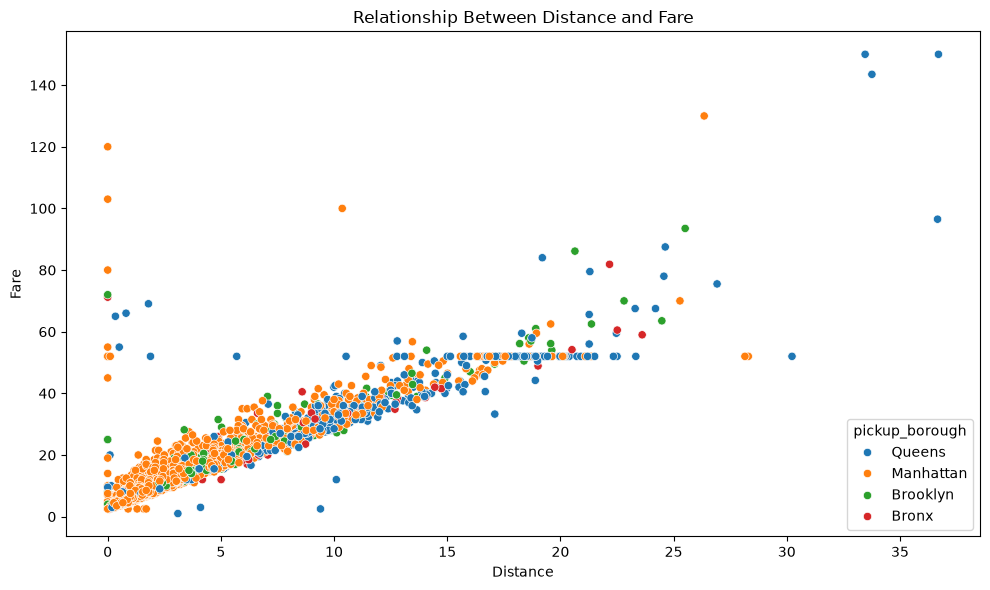

In [34]:
import matplotlib.pyplot as plt
import seaborn as sns

# Create scatter plot
plt.figure(figsize=(10, 6))

sns.scatterplot(
    x='distance',
    y='fare',
    hue='pickup_borough',
    data=df
)

# Add title and labels
plt.title('Relationship Between Distance and Fare')
plt.xlabel('Distance')
plt.ylabel('Fare')

# Display the plot
plt.tight_layout()
plt.show()

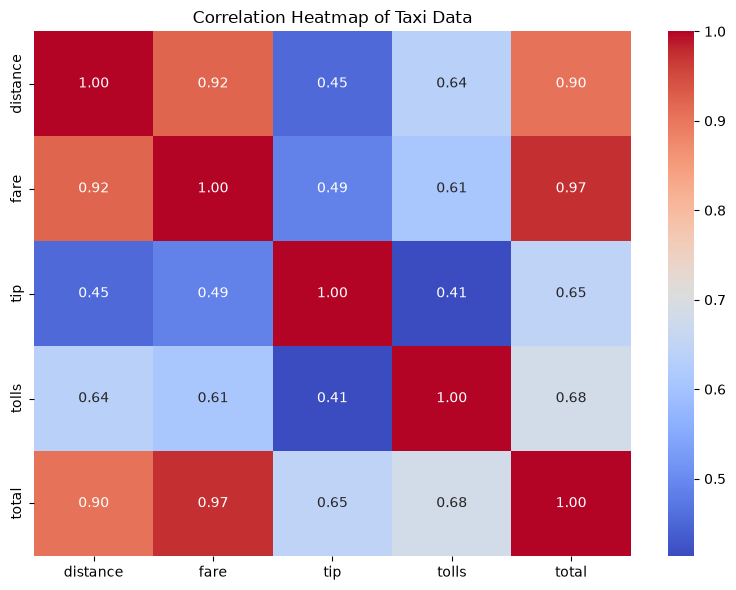

In [35]:
import matplotlib.pyplot as plt
import seaborn as sns

# Select numerical columns
columns = ['distance', 'fare', 'tip', 'tolls', 'total']

# Create correlation matrix
correlation_matrix = df[columns].corr()

# Plot heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt='.2f')

# Add title
plt.title('Correlation Heatmap of Taxi Data')

# Display the heatmap
plt.tight_layout()
plt.show()


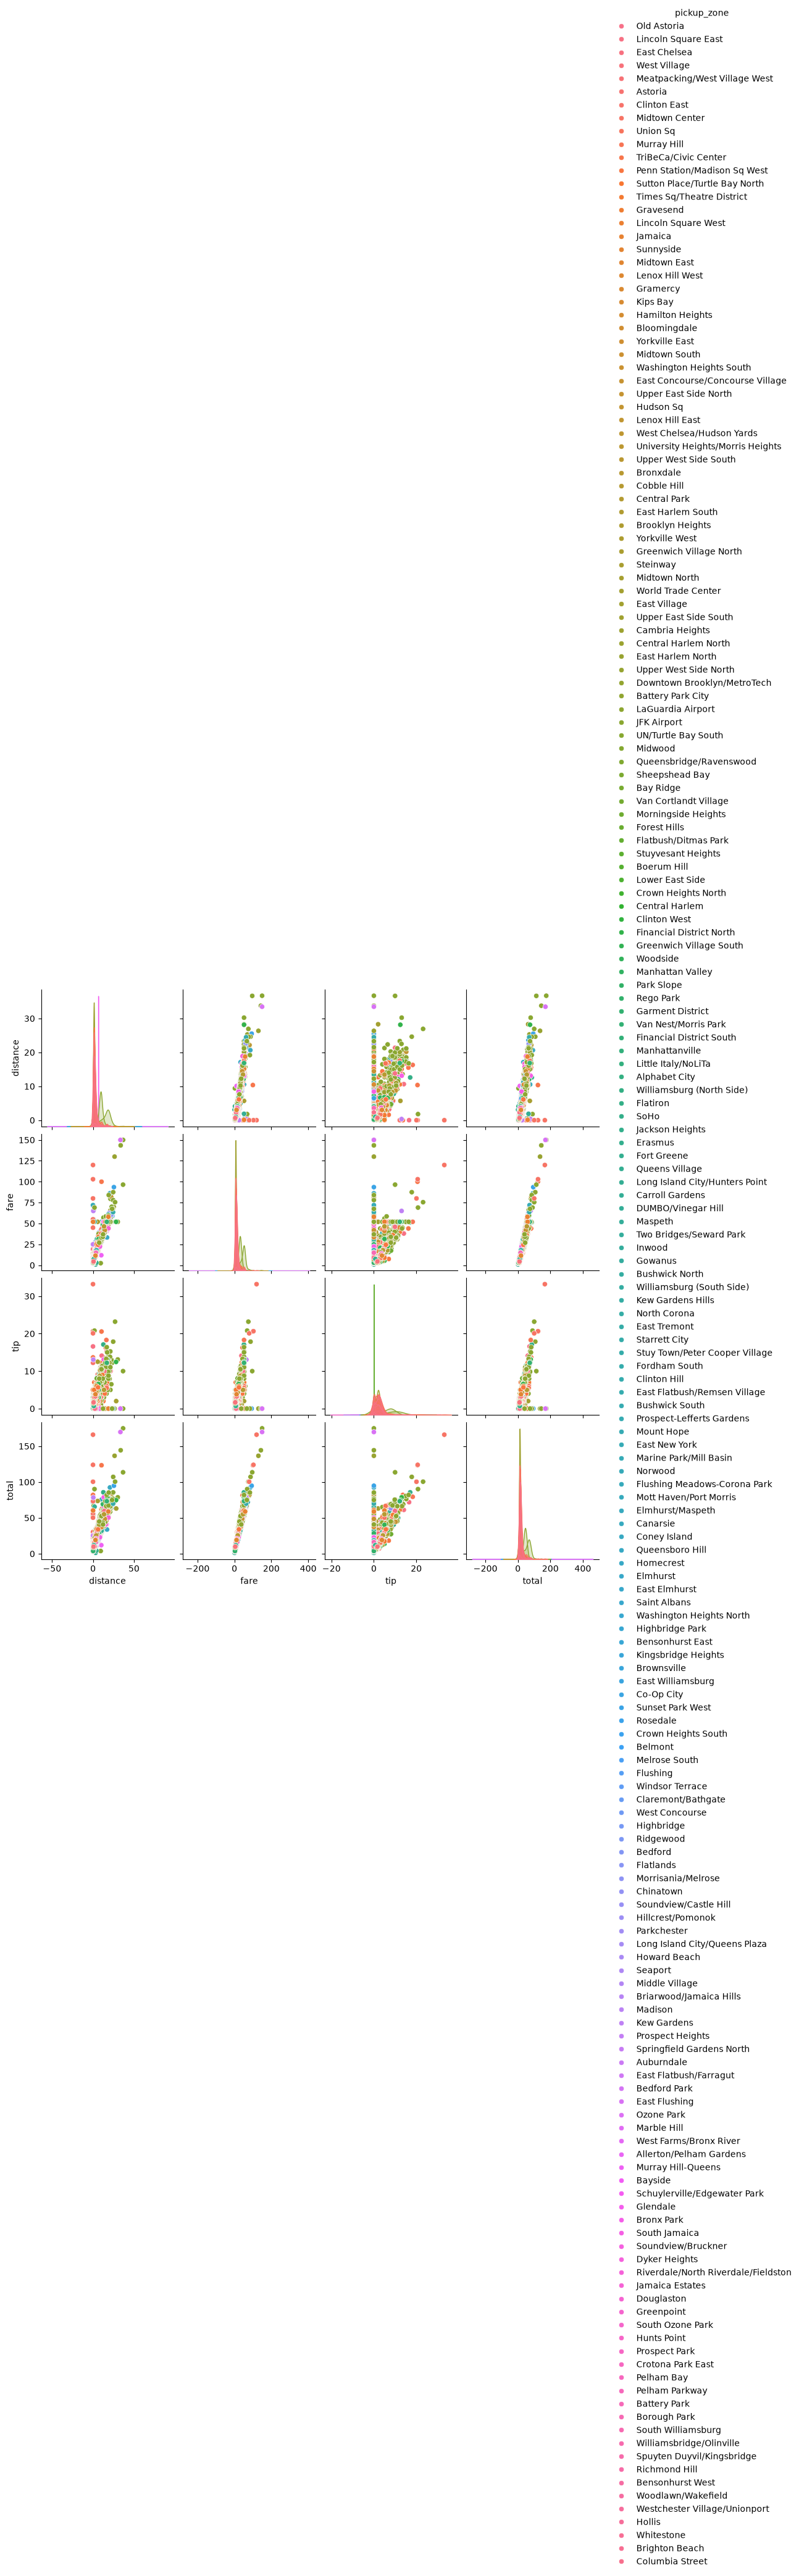

In [51]:
import seaborn as sns
import matplotlib.pyplot as plt

# Select required columns
df_pair = df[['distance', 'fare', 'tip', 'total', 'pickup_zone']]

# Create pair plot
sns.pairplot(df_pair, hue='pickup_zone')

# Display the plot
plt.show()

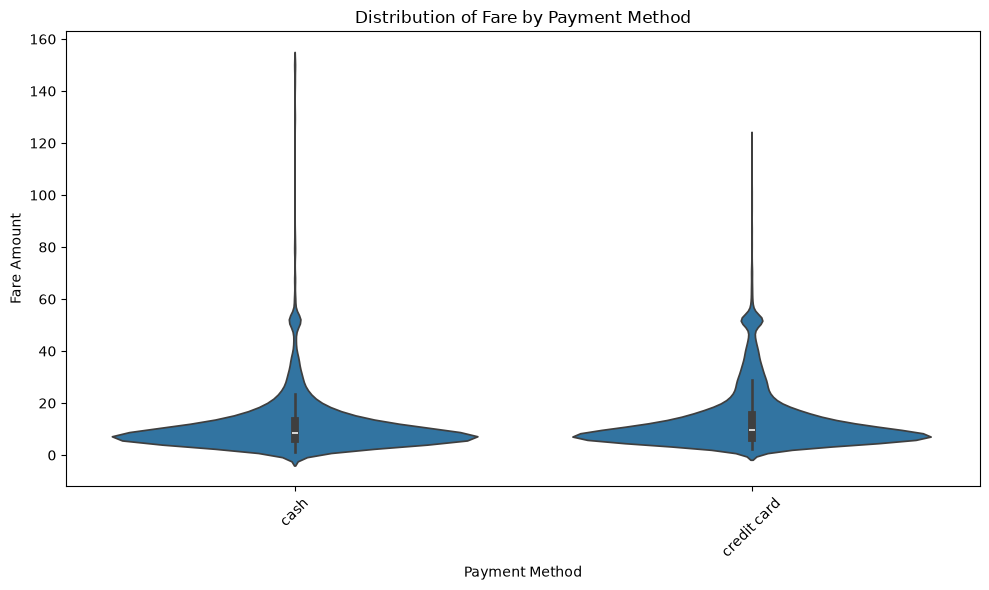

In [46]:
import matplotlib.pyplot as plt
import seaborn as sns

# Create violin plot
plt.figure(figsize=(10, 6))
sns.violinplot(x='payment', y='fare', data=df)

# Add title and labels
plt.title('Distribution of Fare by Payment Method')
plt.xlabel('Payment Method')
plt.ylabel('Fare Amount')

# Display the plot
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()